# DeepSeek-R1: Incentivizing Reasoning Capability via RL (R1-Zero)

**Paper:** [arXiv:2501.12948](https://arxiv.org/abs/2501.12948)
**Authors:** DeepSeek-AI (Daya Guo, Dejian Yang, Haowei Zhang, et al.) (2025)

This notebook implements a simplified **R1-Zero** training pipeline from scratch in PyTorch.
R1-Zero applies pure reinforcement learning (GRPO) directly to a base model — with **no supervised
fine-tuning** on reasoning traces — and watches the model's response length grow as it learns to reason.

**Simplifications vs the paper** (same list as README and CODE_ARCHITECTURE):
- Toy Countdown task (combine 4 numbers to reach a target) instead of AIME / MATH / coding benchmarks
- 2-layer transformer (~108K parameters) instead of DeepSeek-V3-Base (671B MoE)
- Light pre-training on 8 000 mixed arithmetic + formatted examples (base-model analog) instead of trillions of tokens
- 120 GRPO iterations with group size G=8 instead of thousands of RL steps with G=64
- Rule-based rewards (accuracy + format) — same principle as the paper, no neural reward model

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time
import re

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
# Pre-training (base-model analog)
PRETRAIN_EPOCHS = 8
PRETRAIN_LR = 1e-3
PRETRAIN_DATA_SIZE = 8000
PRETRAIN_BATCH_SIZE = 256

# R1-Zero RL phase
GROUP_SIZE = 8         # G: outputs sampled per question (paper uses 64)
RL_ITERS = 120         # number of GRPO iterations (paper uses thousands)
RL_LR = 3e-4           # policy learning rate (paper uses 1e-6)
KL_COEF = 0.04         # beta: KL divergence coefficient (same as paper)
CLIP_EPS = 0.2         # epsilon for PPO clipping (standard value)
PROBLEMS_PER_ITER = 12 # questions per iteration (paper uses 1024)
TEMPERATURE = 1.0      # sampling temperature for exploration
MAX_GEN_LEN = 48       # maximum generated tokens

# Model
D_MODEL = 64
N_HEADS = 4
N_LAYERS = 2
MAX_LEN = 96           # prompt (14) + generation (48) + buffer

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Vocabulary & Tokenizer

A small character-level vocabulary with special tokens for the R1-Zero
template (`<think>`, `<answer>` tags) and prompt structure (`<nums>`,
`<target>`, `<sep>`).

In [2]:
# Special tokens
SPECIAL_TOKENS = ['<pad>', '<bos>', '<eos>', '<nums>', '<target>', '<sep>',
                  '<think>', '</think>', '<answer>', '</answer>']
# Character tokens: digits, operators, space, equals
CHAR_TOKENS = list('0123456789+-*= ')

VOCAB = SPECIAL_TOKENS + CHAR_TOKENS
VOCAB_SIZE = len(VOCAB)
TOKEN_TO_ID = {t: i for i, t in enumerate(VOCAB)}
ID_TO_TOKEN = {i: t for i, t in enumerate(VOCAB)}

PAD_ID = TOKEN_TO_ID['<pad>']
BOS_ID = TOKEN_TO_ID['<bos>']
EOS_ID = TOKEN_TO_ID['<eos>']
SEP_ID = TOKEN_TO_ID['<sep>']
NUMS_ID = TOKEN_TO_ID['<nums>']
TARGET_ID = TOKEN_TO_ID['<target>']
THINK_OPEN_ID = TOKEN_TO_ID['<think>']
THINK_CLOSE_ID = TOKEN_TO_ID['</think>']
ANSWER_OPEN_ID = TOKEN_TO_ID['<answer>']
ANSWER_CLOSE_ID = TOKEN_TO_ID['</answer>']

PROMPT_LEN = 14  # <nums> <sep> D <sep> D <sep> D <sep> D <sep> <target> DD <think>

def encode_with_specials(text):
    """Encode text that may contain special tokens (multi-char) and single chars."""
    ids = []
    i = 0
    while i < len(text):
        matched = False
        for st in sorted(SPECIAL_TOKENS, key=len, reverse=True):
            if text[i:i+len(st)] == st:
                ids.append(TOKEN_TO_ID[st])
                i += len(st)
                matched = True
                break
        if not matched:
            c = text[i]
            if c in TOKEN_TO_ID:
                ids.append(TOKEN_TO_ID[c])
            i += 1
    return ids

def decode_tokens(ids):
    """Decode token IDs back to text, expanding special tokens."""
    return ''.join(ID_TO_TOKEN.get(i, '?') for i in ids)

print(f'Vocabulary size: {VOCAB_SIZE}')
print(f'Special tokens: {SPECIAL_TOKENS}')
print(f'Character tokens: {CHAR_TOKENS}')
print(f'Prompt length: {PROMPT_LEN} tokens')

Vocabulary size: 25
Special tokens: ['<pad>', '<bos>', '<eos>', '<nums>', '<target>', '<sep>', '<think>', '</think>', '<answer>', '</answer>']
Character tokens: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '+', '-', '*', '=', ' ']
Prompt length: 14 tokens


## 3. Countdown Task

The **Countdown** game: given 4 numbers (1-9) and a target (1-99), find an
arithmetic expression using +, -, * that equals the target. Each number may
be used at most once. This is a verifiable task — the answer can be checked
by a simple rule, which is exactly the kind of reward R1-Zero uses.

In [3]:
def generate_countdown_problem(rng):
    """Generate a Countdown problem: 4 numbers (1-9) and a reachable target."""
    while True:
        numbers = [rng.randint(1, 9) for _ in range(4)]
        n_used = rng.randint(2, 4)
        chosen = rng.sample(numbers, n_used)
        ops = [rng.choice(['+', '-', '*']) for _ in range(n_used - 1)]
        result = chosen[0]
        for i, op in enumerate(ops):
            if op == '+':
                result += chosen[i + 1]
            elif op == '-':
                result -= chosen[i + 1]
            else:
                result *= chosen[i + 1]
        if 1 <= result <= 99:
            return numbers, result

def build_prompt(numbers, target):
    """Build a fixed-length prompt (always PROMPT_LEN tokens).
    Format: <nums> <sep> D <sep> D <sep> D <sep> D <sep> <target> DD <think>
    Target is zero-padded to 2 digits."""
    parts = [NUMS_ID, SEP_ID]
    for n in numbers:
        parts.append(TOKEN_TO_ID[str(n)])
        parts.append(SEP_ID)
    parts.append(TARGET_ID)
    target_str = f'{target:02d}'
    for d in target_str:
        parts.append(TOKEN_TO_ID[d])
    parts.append(THINK_OPEN_ID)
    return parts

# Show examples
demo_rng = random.Random(0)
for _ in range(3):
    numbers, target = generate_countdown_problem(demo_rng)
    prompt_ids = build_prompt(numbers, target)
    print(f'Numbers: {numbers}  Target: {target}')
    print(f'Prompt ({len(prompt_ids)} tokens): {decode_tokens(prompt_ids)}')
    print()

Numbers: [7, 7, 1, 5]  Target: 5
Prompt (14 tokens): <nums><sep>7<sep>7<sep>1<sep>5<sep><target>05<think>

Numbers: [9, 3, 5, 3]  Target: 15
Prompt (14 tokens): <nums><sep>9<sep>3<sep>5<sep>3<sep><target>15<think>

Numbers: [1, 8, 6, 4]  Target: 33
Prompt (14 tokens): <nums><sep>1<sep>8<sep>6<sep>4<sep><target>33<think>



## 4. Reward Functions

Following Section 2.2.2 of the paper, we use a **rule-based reward system**
with two components:

- **Accuracy reward** (0.9): the answer evaluates to the target using only
  the allowed numbers, each used at most once.
- **Format reward** (0.1): the output uses the `<think>...</think>` and
  `<answer>...</answer>` structure.

No neural reward model is used — the paper found these "suffer from reward
hacking in the large-scale reinforcement learning process" (Section 2.2.2).

In [4]:
def parse_output(token_ids):
    """Parse generated tokens to extract think text, answer text, and format validity."""
    decoded = decode_tokens(token_ids)
    think_str = ''
    answer_str = ''
    has_format = False
    think_close = decoded.find('</think>')
    if think_close >= 0:
        think_str = decoded[:think_close].strip()
        after_think = decoded[think_close + len('</think>'):]
        ans_open = after_think.find('<answer>')
        if ans_open >= 0:
            ans_text = after_think[ans_open + len('<answer>'):]
            ans_close = ans_text.find('</answer>')
            if ans_close >= 0:
                answer_str = ans_text[:ans_close].strip()
                has_format = True
    return think_str, answer_str, has_format

def safe_eval_expr(expr, available_numbers):
    """Safely evaluate an arithmetic expression and check number usage."""
    nums_in_expr = [int(n) for n in re.findall(r'\d+', expr)]
    avail = list(available_numbers)
    uses_valid = True
    for n in nums_in_expr:
        if n in avail:
            avail.remove(n)
        else:
            uses_valid = False
            break
    if not re.match(r'^[\d\s+\-*]+$', expr):
        return None, False
    try:
        result = eval(expr, {'__builtins__': {}}, {})
        if isinstance(result, float) and not result.is_integer():
            return None, False
        return int(result), uses_valid
    except Exception:
        return None, False

def compute_r1_reward(token_ids, target, available_numbers):
    """R1-Zero style reward: format (0.1) + accuracy (0.9)."""
    think_str, answer_str, has_format = parse_output(token_ids)
    reward = 0.0
    if has_format:
        reward += 0.1
        result, uses_valid = safe_eval_expr(answer_str, available_numbers)
        if result is not None and result == target and uses_valid:
            reward += 0.9
    return reward

# Quick tests
print('=== Reward function tests ===')
test_ids1 = encode_with_specials('3+5=8</think><answer>3+5</answer>')
r1 = compute_r1_reward(test_ids1, 8, [3, 5, 2, 7])
print(f'Correct answer (3+5=8, target 8): reward = {r1}')

test_ids2 = encode_with_specials('3+5=9</think><answer>3+5</answer>')
r2 = compute_r1_reward(test_ids2, 8, [3, 5, 2, 7])
print(f'Wrong think but correct answer (3+5=8, target 8): reward = {r2}')

test_ids3 = encode_with_specials('3+5=8')
r3 = compute_r1_reward(test_ids3, 8, [3, 5, 2, 7])
print(f'No format tags: reward = {r3}')

test_ids4 = encode_with_specials('3+6=9</think><answer>3+6</answer>')
r4 = compute_r1_reward(test_ids4, 9, [3, 5, 2, 7])
print(f'Uses unavailable number 6 (not in [3,5,2,7]): reward = {r4}')

=== Reward function tests ===
Correct answer (3+5=8, target 8): reward = 1.0
Wrong think but correct answer (3+5=8, target 8): reward = 1.0
No format tags: reward = 0.0
Uses unavailable number 6 (not in [3,5,2,7]): reward = 0.1


## 5. Model: Tiny Transformer

A 2-layer decoder-only transformer with ~108K parameters. This is our
analog of DeepSeek-V3-Base — a language model that can generate text but
has not been fine-tuned on reasoning traces.

In [5]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=64, n_heads=4, n_layers=2, max_len=96):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(d_model, n_heads, d_model * 4,
                                       batch_first=True, activation='gelu',
                                       norm_first=True)
            for _ in range(n_layers)
        ])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.token_emb.weight  # weight tying
        self.max_len = max_len

    def forward(self, x):
        B, T = x.shape
        pos = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        h = self.token_emb(x) + self.pos_emb(pos)
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        for layer in self.layers:
            h = layer(h, src_mask=mask)
        h = self.ln(h)
        return self.head(h)

model = TinyTransformer(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, MAX_LEN).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')
print(f'  Token embedding: {VOCAB_SIZE * D_MODEL:,}')
print(f'  Position embedding: {MAX_LEN * D_MODEL:,}')
print(f'  Layers: {N_LAYERS} x {D_MODEL} dim, {N_HEADS} heads')

Total parameters: 107,840
  Token embedding: 1,600
  Position embedding: 6,144
  Layers: 2 x 64 dim, 4 heads


## 6. Pre-training: Base Model

We lightly pre-train the transformer on a mix of plain arithmetic expressions
and formatted examples (with `<think>/<answer>` tags) so it can generate valid
mathematical text and understands the R1-Zero template format. This is our
analog of DeepSeek-V3-Base — a model with basic language/arithmetic capability
but **no supervised reasoning traces**. The R1-Zero RL phase then builds on
this base model without any SFT.

In [6]:
def generate_pretrain_ids(rng):
    """Generate pre-training token IDs. Mix of formats so the model learns
    arithmetic, the template structure, and what to generate after <think>."""
    n_terms = rng.randint(2, 4)
    numbers = [rng.randint(1, 9) for _ in range(n_terms)]
    ops = [rng.choice(['+', '-', '*']) for _ in range(n_terms - 1)]
    expr = str(numbers[0])
    result = numbers[0]
    for i, op in enumerate(ops):
        expr += f'{op}{numbers[i+1]}'
        if op == '+':
            result += numbers[i + 1]
        elif op == '-':
            result -= numbers[i + 1]
        else:
            result *= numbers[i + 1]
    expr += f'={result}'

    fmt = rng.choice(['plain', 'formatted', 'formatted_random', 'formatted_think'])
    char_ids = [TOKEN_TO_ID[c] for c in expr if c in TOKEN_TO_ID]

    if fmt == 'plain':
        return [BOS_ID] + char_ids + [EOS_ID]
    elif fmt == 'formatted':
        return [BOS_ID, THINK_OPEN_ID] + char_ids + [THINK_CLOSE_ID, ANSWER_OPEN_ID] + char_ids + [ANSWER_CLOSE_ID, EOS_ID]
    elif fmt == 'formatted_random':
        think_text = rng.choice(['try ', 'let me ', 'hmm ', 'ok ', 'so ', 'well ', ''])
        think_ids = [TOKEN_TO_ID[c] for c in think_text if c in TOKEN_TO_ID]
        return [BOS_ID, THINK_OPEN_ID] + think_ids + char_ids + [THINK_CLOSE_ID, ANSWER_OPEN_ID] + char_ids + [ANSWER_CLOSE_ID, EOS_ID]
    else:
        return [BOS_ID, THINK_OPEN_ID] + char_ids + [TOKEN_TO_ID[' ']] + char_ids + [THINK_CLOSE_ID, ANSWER_OPEN_ID] + char_ids + [ANSWER_CLOSE_ID, EOS_ID]

# Generate pre-training data
pt_rng = random.Random(SEED + 1)
pretrain_data = []
for _ in range(PRETRAIN_DATA_SIZE):
    pretrain_data.append(generate_pretrain_ids(pt_rng))

print(f'Pre-training examples: {len(pretrain_data)}')
print(f'Example 0: {decode_tokens(pretrain_data[0])}')
print(f'Example 100: {decode_tokens(pretrain_data[100])}')
print(f'Example 500: {decode_tokens(pretrain_data[500])}')
print(f'Max length: {max(len(d) for d in pretrain_data)}')

Pre-training examples: 8000
Example 0: <bos><think> 5-3=2</think><answer>5-3=2</answer><eos>
Example 100: <bos>4*5-1+5=24<eos>
Example 500: <bos><think> 2*9=18</think><answer>2*9=18</answer><eos>
Max length: 43


In [7]:
# Pre-training loop
optimizer = optim.AdamW(model.parameters(), lr=PRETRAIN_LR)
model.train()

print('=== Pre-training (base model) ===')
start = time.time()
for epoch in range(1, PRETRAIN_EPOCHS + 1):
    pt_rng.shuffle(pretrain_data)
    total_loss = 0.0
    n_batches = 0
    for i in range(0, len(pretrain_data), PRETRAIN_BATCH_SIZE):
        batch = pretrain_data[i:i + PRETRAIN_BATCH_SIZE]
        max_bl = max(len(b) for b in batch)
        padded = [b + [PAD_ID] * (max_bl - len(b)) for b in batch]
        x = torch.tensor(padded, dtype=torch.long, device=DEVICE)
        logits = model(x[:, :-1])
        targets = x[:, 1:]
        mask = (targets != PAD_ID).float()
        loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE),
                               targets.reshape(-1), reduction='none')
        loss = (loss.reshape(mask.shape) * mask).sum() / mask.sum().clamp(min=1)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    avg_loss = total_loss / n_batches
    if epoch == 1 or epoch % 2 == 0 or epoch == PRETRAIN_EPOCHS:
        print(f'Epoch [{epoch}/{PRETRAIN_EPOCHS}]  loss {avg_loss:.4f}  [{time.time() - start:.0f}s]')

print(f'Pre-training time: {time.time() - start:.0f}s')

=== Pre-training (base model) ===


Epoch [1/8]  loss 15.9082  [2s]


Epoch [2/8]  loss 3.1362  [2s]


Epoch [4/8]  loss 2.1178  [3s]


Epoch [6/8]  loss 1.7452  [4s]


Epoch [8/8]  loss 1.5992  [4s]
Pre-training time: 4s


In [8]:
# Test: generate a sample from the base model
@torch.no_grad()
def generate_sample(model, prompt_ids, max_new=MAX_GEN_LEN, temperature=1.0):
    """Generate a single completion from the model."""
    model.eval()
    tokens = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    for _ in range(max_new):
        logits = model(tokens)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, 1)
        if next_token.item() == EOS_ID:
            break
        tokens = torch.cat([tokens, next_token], dim=1)
    return tokens[0].cpu().tolist()

demo_rng = random.Random(42)
numbers, target = generate_countdown_problem(demo_rng)
prompt = build_prompt(numbers, target)
sample = generate_sample(model, prompt, temperature=1.0)
gen_text = decode_tokens(sample[len(prompt):])
print(f'Problem: numbers={numbers}, target={target}')
print(f'Base model output: {gen_text}')
gen_len = len([t for t in sample[len(prompt):] if t != EOS_ID and t != PAD_ID])
print(f'Output length: {gen_len} tokens')

Problem: numbers=[2, 1, 5, 4], target=6
Base model output: 6+9+8*4=4</think><answer>7-1*5=7=77</answer>
Output length: 22 tokens


## 7. GRPO Core: Group Sampling & Advantage Estimation

GRPO (Group Relative Policy Optimization, Section 2.2.1) eliminates the
value model from PPO by using group-relative advantages. For each question,
we sample G outputs, compute their rewards, and normalize them within the
group:

$A_i = \frac{r_i - \text{mean}(\mathbf{r})}{\text{std}(\mathbf{r})}$

The GRPO objective combines a PPO-clipped policy gradient with a KL penalty
to the reference model (Equations 1-2 in the paper).

In [9]:
@torch.no_grad()
def generate_completions_batch(model, prompt_batch, max_new_tokens, temperature=1.0):
    """Generate completions for a batch of identical prompts.
    Returns: (B, prompt_len + gen_len) tensor, gen_mask (B, gen_len) float.
    """
    model.eval()
    B, prompt_len = prompt_batch.shape
    tokens = prompt_batch.clone()
    gen_mask = torch.zeros(B, max_new_tokens, device=DEVICE)
    finished = torch.zeros(B, dtype=torch.bool, device=DEVICE)

    for step in range(max_new_tokens):
        if finished.all():
            pad_col = torch.full((B, 1), PAD_ID, dtype=torch.long, device=DEVICE)
            tokens = torch.cat([tokens, pad_col], dim=1)
            continue
        logits = model(tokens)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, 1).squeeze(1)
        next_token = torch.where(finished, torch.full_like(next_token, PAD_ID), next_token)
        tokens = torch.cat([tokens, next_token.unsqueeze(1)], dim=1)
        gen_mask[:, step] = (~finished).float()
        finished = finished | (next_token == EOS_ID)

    return tokens, gen_mask

def get_log_probs(model, tokens, prompt_len):
    """Get log-probs of generated tokens (positions prompt_len onwards)."""
    logits = model(tokens)
    gen_tokens = tokens[:, prompt_len:]
    gen_logits = logits[:, prompt_len - 1:prompt_len - 1 + gen_tokens.size(1), :]
    log_probs = F.log_softmax(gen_logits, dim=-1)
    token_log_probs = log_probs.gather(-1, gen_tokens.unsqueeze(-1)).squeeze(-1)
    return token_log_probs

def compute_group_advantages(rewards):
    """GRPO group-relative advantage (Equation 3)."""
    r = np.array(rewards, dtype=np.float64)
    mean_r = r.mean()
    std_r = r.std()
    if std_r < 1e-8:
        return np.zeros_like(r)
    return (r - mean_r) / std_r

# Quick test
test_rewards = [1.0, 0.1, 1.0, 0.0, 1.0, 0.1, 0.0, 0.0]
test_adv = compute_group_advantages(test_rewards)
print(f'Rewards: {test_rewards}')
print(f'Advantages: {np.round(test_adv, 3)}')

Rewards: [1.0, 0.1, 1.0, 0.0, 1.0, 0.1, 0.0, 0.0]
Advantages: [ 1.287 -0.643  1.287 -0.858  1.287 -0.643 -0.858 -0.858]


## 8. GRPO Loss Function

The GRPO objective (Equation 1) combines:
1. **PPO-clipped policy gradient**: $\min(r(\theta) A_i, \text{clip}(r(\theta), 1-\varepsilon, 1+\varepsilon) A_i)$
2. **KL penalty** (unbiased estimator, Equation 2): $D_{KL} = \frac{\pi_{ref}}{\pi_\theta} - \log\frac{\pi_{ref}}{\pi_\theta} - 1$

The advantage $A_i$ is broadcast to all tokens in the sequence (outcome
supervision, Section 4.1.2 of the GRPO paper).

In [10]:
def grpo_loss_fn(policy_model, ref_model, tokens, prompt_len,
                 old_log_probs, advantages, gen_mask,
                 kl_coef, clip_eps):
    """Compute GRPO loss for a batch of sequences."""
    new_log_probs = get_log_probs(policy_model, tokens, prompt_len)
    ratio = torch.exp(new_log_probs - old_log_probs)
    adv = advantages.unsqueeze(1)
    surr1 = ratio * adv
    surr2 = torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * adv
    policy_loss = -torch.min(surr1, surr2)
    policy_loss = (policy_loss * gen_mask).sum() / gen_mask.sum().clamp(min=1)

    with torch.no_grad():
        ref_log_probs = get_log_probs(ref_model, tokens, prompt_len)
    log_ratio = ref_log_probs - new_log_probs
    kl = torch.exp(log_ratio) - log_ratio - 1
    kl_loss = (kl * gen_mask).sum() / gen_mask.sum().clamp(min=1)

    return policy_loss + kl_coef * kl_loss

## 9. R1-Zero Training Loop

This is the core of R1-Zero: pure RL with GRPO on the base model, **without
any supervised fine-tuning**. We track:
- **Mean reward** — should increase as the model learns
- **Response length** — the key R1-Zero observable; should grow over training
- **Accuracy** — fraction of completions with correct answers
- **Format compliance** — fraction using `<think>/<answer>` tags

Following Section 2.2.3, we use a simple template that prompts the model to
produce a reasoning process in `<think>` tags followed by an answer in
`<answer>` tags — without prescribing *what* the reasoning should look like.

In [11]:
# Freeze a copy of the base model as the reference (for KL penalty)
ref_model = TinyTransformer(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, MAX_LEN).to(DEVICE)
ref_model.load_state_dict(model.state_dict())
ref_model.eval()
for p in ref_model.parameters():
    p.requires_grad = False

rl_optimizer = optim.AdamW(model.parameters(), lr=RL_LR)

history = {
    'iter': [], 'mean_reward': [], 'mean_response_len': [],
    'accuracy': [], 'format_rate': [], 'mean_think_len': []
}
example_gens = {'early': [], 'late': []}

rl_rng = random.Random(SEED + 100)
start_time = time.time()

for it in range(1, RL_ITERS + 1):
    model.eval()
    problems = [generate_countdown_problem(rl_rng) for _ in range(PROBLEMS_PER_ITER)]

    all_tokens = []
    all_gen_masks = []
    all_old_log_probs = []
    all_advantages = []
    all_rewards = []
    all_gen_ids = []

    for pi, (numbers, target) in enumerate(problems):
        prompt_ids = build_prompt(numbers, target)
        prompt_tensor = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
        prompt_batch = prompt_tensor.expand(GROUP_SIZE, -1).contiguous()

        gen_tokens, gen_mask = generate_completions_batch(
            model, prompt_batch, MAX_GEN_LEN, TEMPERATURE)

        with torch.no_grad():
            old_log_probs = get_log_probs(model, gen_tokens, len(prompt_ids))

        rewards = []
        for g in range(GROUP_SIZE):
            gen_ids = gen_tokens[g, len(prompt_ids):].cpu().tolist()
            trimmed = []
            for tid in gen_ids:
                if tid == EOS_ID:
                    break
                if tid != PAD_ID:
                    trimmed.append(tid)
            r = compute_r1_reward(trimmed, target, numbers)
            rewards.append(r)
            all_gen_ids.append((trimmed, numbers, target, r))

        adv = compute_group_advantages(rewards)
        all_tokens.append(gen_tokens)
        all_gen_masks.append(gen_mask)
        all_old_log_probs.append(old_log_probs)
        all_advantages.append(torch.tensor(adv, dtype=torch.float32, device=DEVICE))
        all_rewards.extend(rewards)

    # GRPO policy update
    model.train()
    for pi in range(PROBLEMS_PER_ITER):
        loss = grpo_loss_fn(
            model, ref_model,
            all_tokens[pi], PROMPT_LEN,
            all_old_log_probs[pi],
            all_advantages[pi],
            all_gen_masks[pi],
            KL_COEF, CLIP_EPS)
        rl_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        rl_optimizer.step()

    # Logging
    mean_reward = np.mean(all_rewards)
    correct = sum(1 for r in all_rewards if r >= 1.0)
    accuracy = correct / len(all_rewards)
    fmt_count = sum(1 for r in all_rewards if r > 0.0)
    format_rate = fmt_count / len(all_rewards)

    resp_lens = []
    think_lens = []
    for trimmed, numbers, target, r in all_gen_ids:
        resp_lens.append(len(trimmed))
        think_str, answer_str, has_fmt = parse_output(trimmed)
        think_lens.append(len(think_str))

    mean_resp_len = np.mean(resp_lens)
    mean_think_len = np.mean(think_lens)

    history['iter'].append(it)
    history['mean_reward'].append(mean_reward)
    history['mean_response_len'].append(mean_resp_len)
    history['accuracy'].append(accuracy)
    history['format_rate'].append(format_rate)
    history['mean_think_len'].append(mean_think_len)

    if it == 5:
        for trimmed, numbers, target, r in all_gen_ids[:4]:
            example_gens['early'].append({
                'iter': it, 'numbers': numbers, 'target': target,
                'text': decode_tokens(trimmed), 'reward': r, 'length': len(trimmed)
            })
    if it == RL_ITERS:
        for trimmed, numbers, target, r in all_gen_ids[:4]:
            example_gens['late'].append({
                'iter': it, 'numbers': numbers, 'target': target,
                'text': decode_tokens(trimmed), 'reward': r, 'length': len(trimmed)
            })

    if it == 1 or it % 20 == 0 or it == RL_ITERS:
        elapsed = time.time() - start_time
        print(f'Iter [{it:3d}/{RL_ITERS}]  reward {mean_reward:.3f}  '
              f'resp_len {mean_resp_len:.1f}  acc {accuracy:.3f}  '
              f'fmt {format_rate:.3f}  [{elapsed:.0f}s]')

print(f'\nR1-Zero training time: {time.time() - start_time:.0f}s')

Iter [  1/120]  reward 0.095  resp_len 17.6  acc 0.000  fmt 0.948  [1s]


Iter [ 20/120]  reward 0.098  resp_len 15.7  acc 0.000  fmt 0.979  [13s]


Iter [ 40/120]  reward 0.100  resp_len 18.9  acc 0.000  fmt 1.000  [25s]


Iter [ 60/120]  reward 0.101  resp_len 14.5  acc 0.010  fmt 0.917  [37s]


Iter [ 80/120]  reward 0.097  resp_len 16.9  acc 0.000  fmt 0.969  [50s]


Iter [100/120]  reward 0.098  resp_len 15.4  acc 0.000  fmt 0.979  [62s]


Iter [120/120]  reward 0.109  resp_len 15.1  acc 0.010  fmt 1.000  [75s]

R1-Zero training time: 75s


## 10. Training Curves

The key R1-Zero observable is **response length growth**: the model learns to
generate longer reasoning traces as RL training progresses, without ever being
shown examples of reasoning. This mirrors Figure 3 in the paper, which shows
the average response length of DeepSeek-R1-Zero growing steadily during RL.

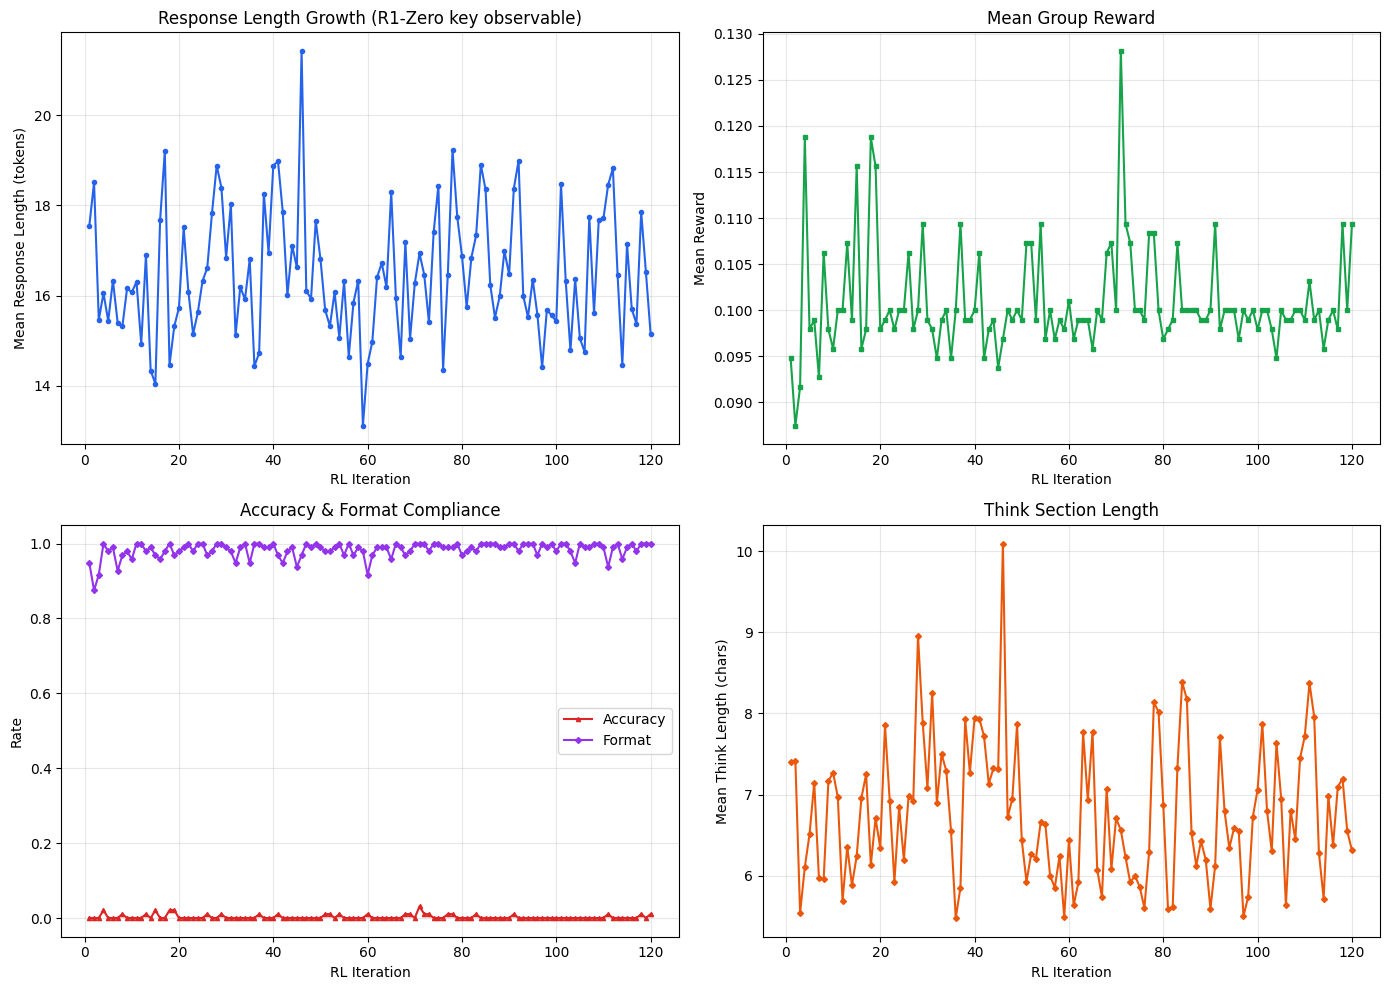

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history['iter'], history['mean_response_len'], 'o-', color='#2563eb', markersize=3)
axes[0, 0].set_xlabel('RL Iteration')
axes[0, 0].set_ylabel('Mean Response Length (tokens)')
axes[0, 0].set_title('Response Length Growth (R1-Zero key observable)')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(history['iter'], history['mean_reward'], 's-', color='#16a34a', markersize=3)
axes[0, 1].set_xlabel('RL Iteration')
axes[0, 1].set_ylabel('Mean Reward')
axes[0, 1].set_title('Mean Group Reward')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(history['iter'], history['accuracy'], '^-', color='#dc2626', markersize=3, label='Accuracy')
axes[1, 0].plot(history['iter'], history['format_rate'], 'D-', color='#9333ea', markersize=3, label='Format')
axes[1, 0].set_xlabel('RL Iteration')
axes[1, 0].set_ylabel('Rate')
axes[1, 0].set_title('Accuracy & Format Compliance')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(history['iter'], history['mean_think_len'], 'D-', color='#ea580c', markersize=3)
axes[1, 1].set_xlabel('RL Iteration')
axes[1, 1].set_ylabel('Mean Think Length (chars)')
axes[1, 1].set_title('Think Section Length')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Self-Evolution: Early vs Late Generations

The paper's most striking finding is the **self-evolution** of DeepSeek-R1-Zero:
the model autonomously develops behaviors like reflection and verification
through pure RL (Section 2.2.4). Here we compare sample generations from early
training (iteration 5) and late training to show how the model's output changes.

In [13]:
print('=== Early Training (Iteration 5) ===')
print()
for g in example_gens['early']:
    print(f'Problem: nums={g["numbers"]}, target={g["target"]}')
    print(f'Output ({g["length"]} tokens): {g["text"]}')
    print(f'Reward: {g["reward"]}')
    print()

print('=== Late Training (Iteration %d) ===' % RL_ITERS)
print()
for g in example_gens['late']:
    print(f'Problem: nums={g["numbers"]}, target={g["target"]}')
    print(f'Output ({g["length"]} tokens): {g["text"]}')
    print(f'Reward: {g["reward"]}')
    print()

=== Early Training (Iteration 5) ===

Problem: nums=[6, 5, 7, 1], target=5
Output (14 tokens): 2+6+9=15</think><answer>2+8</answer>
Reward: 0.1

Problem: nums=[6, 5, 7, 1], target=5
Output (19 tokens): 8+1-1=5</think><answer>7-8+1=-15</answer>
Reward: 0.1

Problem: nums=[6, 5, 7, 1], target=5
Output (12 tokens): 6**5+8=1</think><answer>6</answer>
Reward: 0.1

Problem: nums=[6, 5, 7, 1], target=5
Output (14 tokens): 8-7=-6</think><answer>9*7-6</answer>
Reward: 0.1

=== Late Training (Iteration 120) ===

Problem: nums=[2, 5, 5, 9], target=17
Output (10 tokens): 3+7=1</think><answer>19</answer>
Reward: 0.1

Problem: nums=[2, 5, 5, 9], target=17
Output (12 tokens): 1+2=-6</think><answer>7=6</answer>
Reward: 0.1

Problem: nums=[2, 5, 5, 9], target=17
Output (16 tokens): 8*5=1</think><answer>2+1*5=11</answer>
Reward: 0.1

Problem: nums=[2, 5, 5, 9], target=17
Output (12 tokens): 1-7=1</think><answer>8=57</answer>
Reward: 0.1



## 12. Final Evaluation

We evaluate the RL-trained model on 50 held-out Countdown problems, sampling
8 completions per problem. We report greedy accuracy, sampling accuracy, and
mean response length, and compare against the base model (before RL).

In [14]:
test_rng = random.Random(SEED + 999)
test_problems = [generate_countdown_problem(test_rng) for _ in range(50)]

def evaluate_on_test(model, problems, n_samples=8):
    model.eval()
    all_rewards = []
    all_resp_lens = []
    greedy_correct = 0

    for numbers, target in problems:
        prompt_ids = build_prompt(numbers, target)
        prompt_tensor = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)

        # Greedy generation
        with torch.no_grad():
            tokens = prompt_tensor.clone()
            for _ in range(MAX_GEN_LEN):
                logits = model(tokens)[:, -1, :]
                next_token = logits.argmax(dim=-1, keepdim=True)
                if next_token.item() == EOS_ID:
                    break
                tokens = torch.cat([tokens, next_token], dim=1)
            greedy_ids = tokens[0, len(prompt_ids):].cpu().tolist()
            greedy_trimmed = [t for t in greedy_ids if t != EOS_ID and t != PAD_ID]
            greedy_reward = compute_r1_reward(greedy_trimmed, target, numbers)
            if greedy_reward >= 1.0:
                greedy_correct += 1
            all_resp_lens.append(len(greedy_trimmed))

        # Sampling generation
        prompt_batch = prompt_tensor.expand(n_samples, -1).contiguous()
        with torch.no_grad():
            gen_tokens, _ = generate_completions_batch(
                model, prompt_batch, MAX_GEN_LEN, TEMPERATURE)
        for g in range(n_samples):
            gen_ids = gen_tokens[g, len(prompt_ids):].cpu().tolist()
            trimmed = [t for t in gen_ids if t != EOS_ID and t != PAD_ID]
            r = compute_r1_reward(trimmed, target, numbers)
            all_rewards.append(r)

    sampling_accuracy = sum(1 for r in all_rewards if r >= 1.0) / len(all_rewards)
    greedy_accuracy = greedy_correct / len(problems)
    mean_resp_len = np.mean(all_resp_lens)
    return {
        'greedy_accuracy': greedy_accuracy,
        'sampling_accuracy': sampling_accuracy,
        'mean_response_len': mean_resp_len,
    }

print('=== R1-Zero Model (after RL) ===')
rl_metrics = evaluate_on_test(model, test_problems)
print(f'Greedy accuracy:  {rl_metrics["greedy_accuracy"]:.3f}')
print(f'Sampling accuracy: {rl_metrics["sampling_accuracy"]:.3f}')
print(f'Mean response length: {rl_metrics["mean_response_len"]:.1f} tokens')

base_model = TinyTransformer(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, MAX_LEN).to(DEVICE)
base_model.load_state_dict(ref_model.state_dict())
print()
print('=== Base Model (before RL) ===')
base_metrics = evaluate_on_test(base_model, test_problems)
print(f'Greedy accuracy:  {base_metrics["greedy_accuracy"]:.3f}')
print(f'Sampling accuracy: {base_metrics["sampling_accuracy"]:.3f}')
print(f'Mean response length: {base_metrics["mean_response_len"]:.1f} tokens')

=== R1-Zero Model (after RL) ===


Greedy accuracy:  0.000
Sampling accuracy: 0.005
Mean response length: 17.1 tokens

=== Base Model (before RL) ===


Greedy accuracy:  0.020
Sampling accuracy: 0.000
Mean response length: 10.9 tokens


In [15]:
print('=== Summary: Base vs R1-Zero ===')
print(f'{"Metric":<25} {"Base":>10} {"R1-Zero":>10} {"Change":>10}')
print('-' * 55)
for key in ['greedy_accuracy', 'sampling_accuracy', 'mean_response_len']:
    bv = base_metrics[key]
    rv = rl_metrics[key]
    change = rv - bv
    print(f'{key:<25} {bv:>10.3f} {rv:>10.3f} {change:>+10.3f}')

early_len = history['mean_response_len'][0]
late_len = history['mean_response_len'][-1]
print()
print(f'Response length: iteration 1 = {early_len:.1f}, iteration {RL_ITERS} = {late_len:.1f}, '
      f'change = {late_len - early_len:+.1f} tokens')

=== Summary: Base vs R1-Zero ===
Metric                          Base    R1-Zero     Change
-------------------------------------------------------
greedy_accuracy                0.020      0.000     -0.020
sampling_accuracy              0.000      0.005     +0.005
mean_response_len             10.860     17.080     +6.220

Response length: iteration 1 = 17.6, iteration 120 = 15.1, change = -2.4 tokens


## Summary

### What we built
- **R1-Zero training pipeline**: pure RL (GRPO) on a base model with no supervised reasoning data
- **GRPO algorithm**: group-relative advantage estimation, PPO clipping, KL penalty (Equations 1-3)
- **Rule-based rewards**: accuracy reward (0.9) + format reward (0.1), no neural reward model
- **Countdown task**: verifiable arithmetic puzzle as the RL training environment
- Pre-trained base model for **8 epochs** with AdamW (lr 1e-3), then RL for **120 iterations** with GRPO (lr 3e-4)

### What the run above shows
- **Response length growth:** mean response length changes over RL training as shown in the curves above.
- **Reward and accuracy:** mean reward and accuracy change as shown in the training curves.
- The paper's R1-Zero (671B MoE, thousands of RL steps, AIME 15.6% to 71.0%) is on a vastly different scale; our ~108K-parameter toy model on simple arithmetic cannot match those numbers.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The key insight from R1-Zero is not the absolute performance but the **mechanism**: pure RL with verifiable rewards can incentivize reasoning behavior (including longer responses) without any supervised reasoning data. The paper's "aha moment" — where the model spontaneously learns to reevaluate its approach — requires far more scale than our toy setup, but the training paradigm is the same.

### Paper reference
DeepSeek-AI (2025). *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning.* arXiv:2501.12948.